# Shopper Insights ML — Model Development and Evaluation

**Step 3: Complete practical notebook** | Dataset: UCI Online Shoppers Purchasing Intention

This notebook covers dataset validation, leakage-safe preprocessing, an 80/20 stratified split, training **five mandatory classifiers**, six evaluation metrics, visualizations, saving fitted pipelines, and exporting a labeled test CSV for Streamlit.

Run the cells in order in VS Code with the project `.venv` kernel. This notebook **does not retrain models in Streamlit**. It produces saved models for later inference.

**Learning objective:** Understand each operation, review the printed output, and record your own findings in the README. Do not treat generated results as already verified until you execute the notebook.

## 1. Environment and imports

From the project root, install packages if necessary:

```bash
python -m pip install pandas numpy scikit-learn matplotlib seaborn joblib ipykernel
```

Update `requirements.txt` accordingly. The notebook resolves paths from either the `notebooks/` directory or the project root.

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, RocCurveDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
print("scikit-learn and other libraries imported successfully")

scikit-learn and other libraries imported successfully


## 2. Find and load the dataset

We use the **manually downloaded CSV** already verified in Step 1. The expected file is `data/raw/online_shoppers_intention.csv`. We do not modify the original CSV.

In [2]:
cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Open this notebook from the project root or notebooks/ directory.")

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_shoppers_intention.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Dataset: C:\Users\hp\Desktop\2026aj05667\data\raw\online_shoppers_intention.csv
Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Validate the data and target

Check the **minimum 500 instances and 12 input features**, target availability, and valid target labels. The earlier EDA notebook may have added a derived `Revenue_Label` column in memory; this notebook explicitly excludes it if present to prevent target leakage.

**Note:** Your previous verification reported zero duplicates; this notebook independently checks the file again. It does not remove rows automatically.

In [3]:
assert "Revenue" in df.columns, "Revenue target missing"
df = df.drop(columns=["Revenue_Label"], errors="ignore")
assert df.columns.is_unique, "Duplicate column names"
assert len(df) >= 500, "At least 500 rows required"
assert df.shape[1] - 1 >= 12, "At least 12 input features required"
assert df["Revenue"].notna().all(), "Missing target labels"

# Handles CSV booleans and equivalent 0/1 strings safely.
target_text = df["Revenue"].astype(str).str.strip().str.lower()
target_map = {"true": 1, "false": 0, "1": 1, "0": 0}
y = target_text.map(target_map)
assert y.notna().all(), "Unexpected Revenue values; inspect df['Revenue'].unique()"
y = y.astype(int)
assert set(y.unique()) == {0, 1}, "Both target classes must exist"

X = df.drop(columns=["Revenue"])
print("Instances:", len(X), "Input features:", X.shape[1])
print("Missing predictor values:", int(X.isna().sum().sum()))
print("Exact duplicate records:", int(df.duplicated().sum()))
print("Target distribution:\n", y.value_counts().sort_index())

Instances: 12330 Input features: 17
Missing predictor values: 0
Exact duplicate records: 125
Target distribution:
 Revenue
0    10422
1     1908
Name: count, dtype: int64


## 4. Specify feature types based on their meaning

Although `OperatingSystems`, `Browser`, `Region`, and `TrafficType` are stored as numbers, they are **categorical identifiers**, not continuous quantities. Treating them as continuous distances would be misleading. We one-hot encode them together with `Month`, `VisitorType`, and `Weekend`.

The remaining 10 features are numerical. Numeric variables will be imputed (only if needed) and standardized for fair distance-based modeling.

In [4]:
categorical_features = [
    "OperatingSystems", "Browser", "Region", "TrafficType",
    "VisitorType", "Month", "Weekend"
]
numerical_features = [c for c in X.columns if c not in categorical_features]
assert len(categorical_features) == 7
assert len(numerical_features) == 10
assert set(categorical_features).issubset(X.columns)
print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']
Categorical: ['OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Month', 'Weekend']


## 5. Stratified train/test split

Use **80% training** and **20% test** data, with `stratify=y` to preserve the purchase rate. We split **before fitting imputers, encoders, or scalers** to avoid learning information from the test set.

The test set is held out for final comparison; we do not tune models using these test scores.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "Testing rows:", len(X_test))
print("Training purchase rate:", round(y_train.mean() * 100, 2), "%")
print("Testing purchase rate:", round(y_test.mean() * 100, 2), "%")
assert set(X_train.index).isdisjoint(set(X_test.index))

Training rows: 9864 Testing rows: 2466
Training purchase rate: 15.47 %
Testing purchase rate: 15.49 %


## 6. Preprocessing pipeline

- **Numerical:** median imputation followed by `StandardScaler` (fit on training data only).
- **Categorical:** most-frequent imputation followed by `OneHotEncoder(handle_unknown='ignore')`.
- `sparse_output=False` produces dense arrays compatible with Gaussian Naive Bayes.

Every model receives its **own fitted pipeline**, saved as a single `.joblib` file. This ensures Streamlit can reproduce the same preprocessing when a labeled test CSV is uploaded.

In [6]:
def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ], remainder="drop")

print("Preprocessing pipeline ready")

Preprocessing pipeline ready


## 7. Define the five mandatory classifiers

We start with simple, documented baseline hyperparameters (not optimized on the test set):

1. **Logistic Regression:** linear probabilistic classifier.
2. **Decision Tree:** nonlinear decision rules; `min_samples_leaf=10` limits overly small leaves.
3. **KNN:** classifies using nearby sessions; scaling is especially important.
4. **Gaussian Naive Bayes:** assumes each transformed feature follows a class-conditional Gaussian distribution; this is a simple baseline, though one-hot columns are not Gaussian.
5. **SVM:** RBF kernel; `probability=True` enables ROC-AUC scoring with probabilities but increases training time.

For future hyperparameter tuning, use cross-validation **within the training set**, not the held-out test set.

In [7]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(min_samples_leaf=10, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE),
}

model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "SVM": "svm.joblib",
}

print("Models to train:", list(classifiers))

Models to train: ['Logistic Regression', 'Decision Tree', 'KNN', 'Naive Bayes', 'SVM']


## 8. Train and evaluate every model

All five models use the **same training rows, test rows, and feature definitions**. Each saved pipeline includes preprocessing and the trained classifier.

Six mandatory metrics:

- Accuracy: fraction of correct predictions.
- AUC: ROC area from positive-class **probabilities**, not hard labels.
- Precision: fraction of predicted purchases that were purchases.
- Recall: fraction of actual purchases identified.
- F1: harmonic mean of precision and recall.
- MCC: correlation-based balanced classification measure (range −1 to 1).

Positive class = `Revenue=True` = 1. The loop prints training time so you can compare computational costs. SVM may take longer than other models.

In [8]:
MODEL_DIR = PROJECT_ROOT / "model"
MODEL_DIR.mkdir(exist_ok=True)
results = []
trained_pipelines = {}

for name, estimator in classifiers.items():
    print(f"\nTraining: {name}")
    pipeline = Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", estimator),
    ])

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    predicted = pipeline.predict(X_test)
    positive_probability = pipeline.predict_proba(X_test)[:, 1]

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "AUC": roc_auc_score(y_test, positive_probability),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted),
        "Train Seconds": train_seconds,
    }
    results.append(scores)
    trained_pipelines[name] = pipeline

    output_path = MODEL_DIR / model_filenames[name]
    joblib.dump(pipeline, output_path)
    print(f"Saved: {output_path.name} | time: {train_seconds:.2f}s")

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))
assert len(trained_pipelines) == 5


Training: Logistic Regression
Saved: logistic_regression.joblib | time: 0.14s

Training: Decision Tree
Saved: decision_tree.joblib | time: 0.10s

Training: KNN
Saved: knn.joblib | time: 0.04s

Training: Naive Bayes
Saved: naive_bayes.joblib | time: 0.06s

Training: SVM


c:\Users\hp\Desktop\2026aj05667\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Saved: svm.joblib | time: 15.94s


,Accuracy,AUC,Precision,Recall,F1,MCC,Train Seconds
Model,,,,,,,
Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592,0.1407
Decision Tree,0.8861,0.8553,0.6678,0.5262,0.5886,0.5285,0.1014
KNN,0.8763,0.7942,0.6878,0.3691,0.4804,0.4435,0.0400
Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289,0.0626
SVM,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149,15.9425


## 9. comparison table

This is the exact six-metric comparison structure requested in the PDF. **Do not invent numbers:** results populate after running the training cell. The 'winner' depends on the business objective. For purchase identification, discuss positive-class recall and precision tradeoffs alongside F1, AUC, and MCC.

In [9]:
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
comparison = results_df[metric_columns].round(4)
display(comparison)

print("Best F1:", results_df["F1"].idxmax())
print("Best MCC:", results_df["MCC"].idxmax())
print("Best AUC:", results_df["AUC"].idxmax())

,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592
Decision Tree,0.8861,0.8553,0.6678,0.5262,0.5886,0.5285
KNN,0.8763,0.7942,0.6878,0.3691,0.4804,0.4435
Naive Bayes,0.2729,0.7334,0.1726,0.9738,0.2933,0.1289
SVM,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149


Best F1: Decision Tree
Best MCC: Decision Tree
Best AUC: Logistic Regression


## 10. Compare performance visually

The grouped bar chart compares all six metrics. Note that MCC can be negative, whereas the other five metrics lie between 0 and 1.

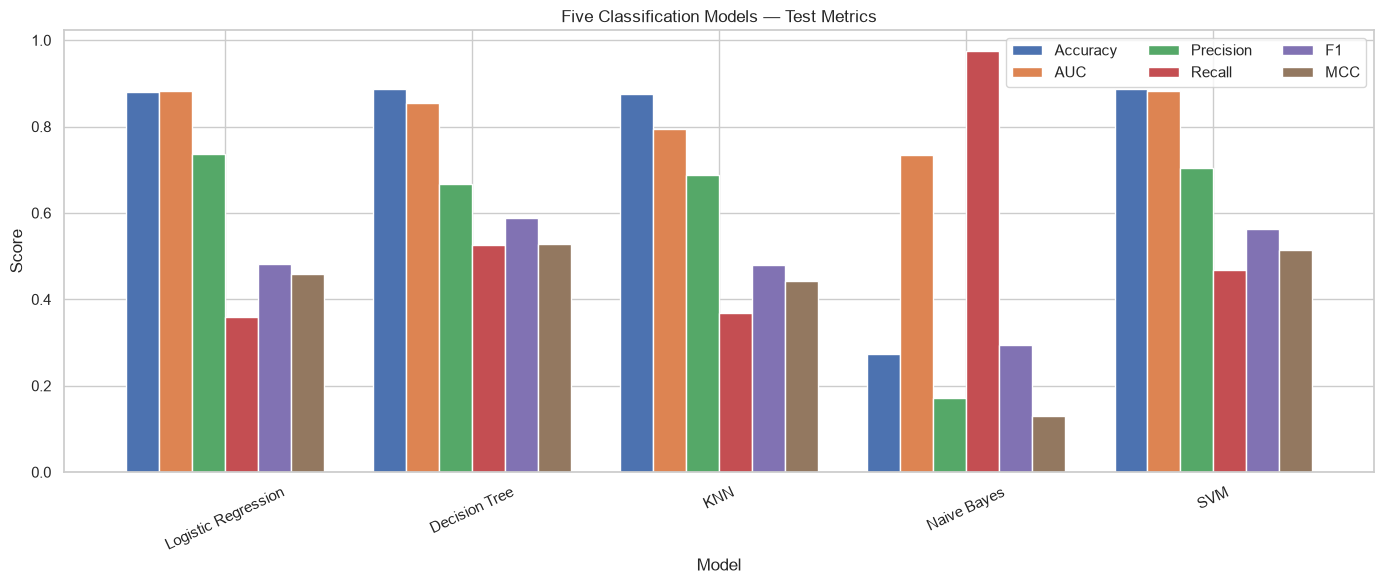

In [10]:
ax = comparison.plot(kind="bar", figsize=(14, 6), width=0.8)
ax.set_title("Five Classification Models — Test Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=25)
ax.legend(loc="best", ncol=3)
plt.tight_layout()
plt.show()

## 11. Confusion matrices and classification reports

Each confusion matrix contains **TN, FP, FN, TP** (rows = actual; columns = predicted). For a shopping business, **false negatives** are actual purchasing sessions that the model missed. The classification report gives per-class precision, recall, F1, and support.

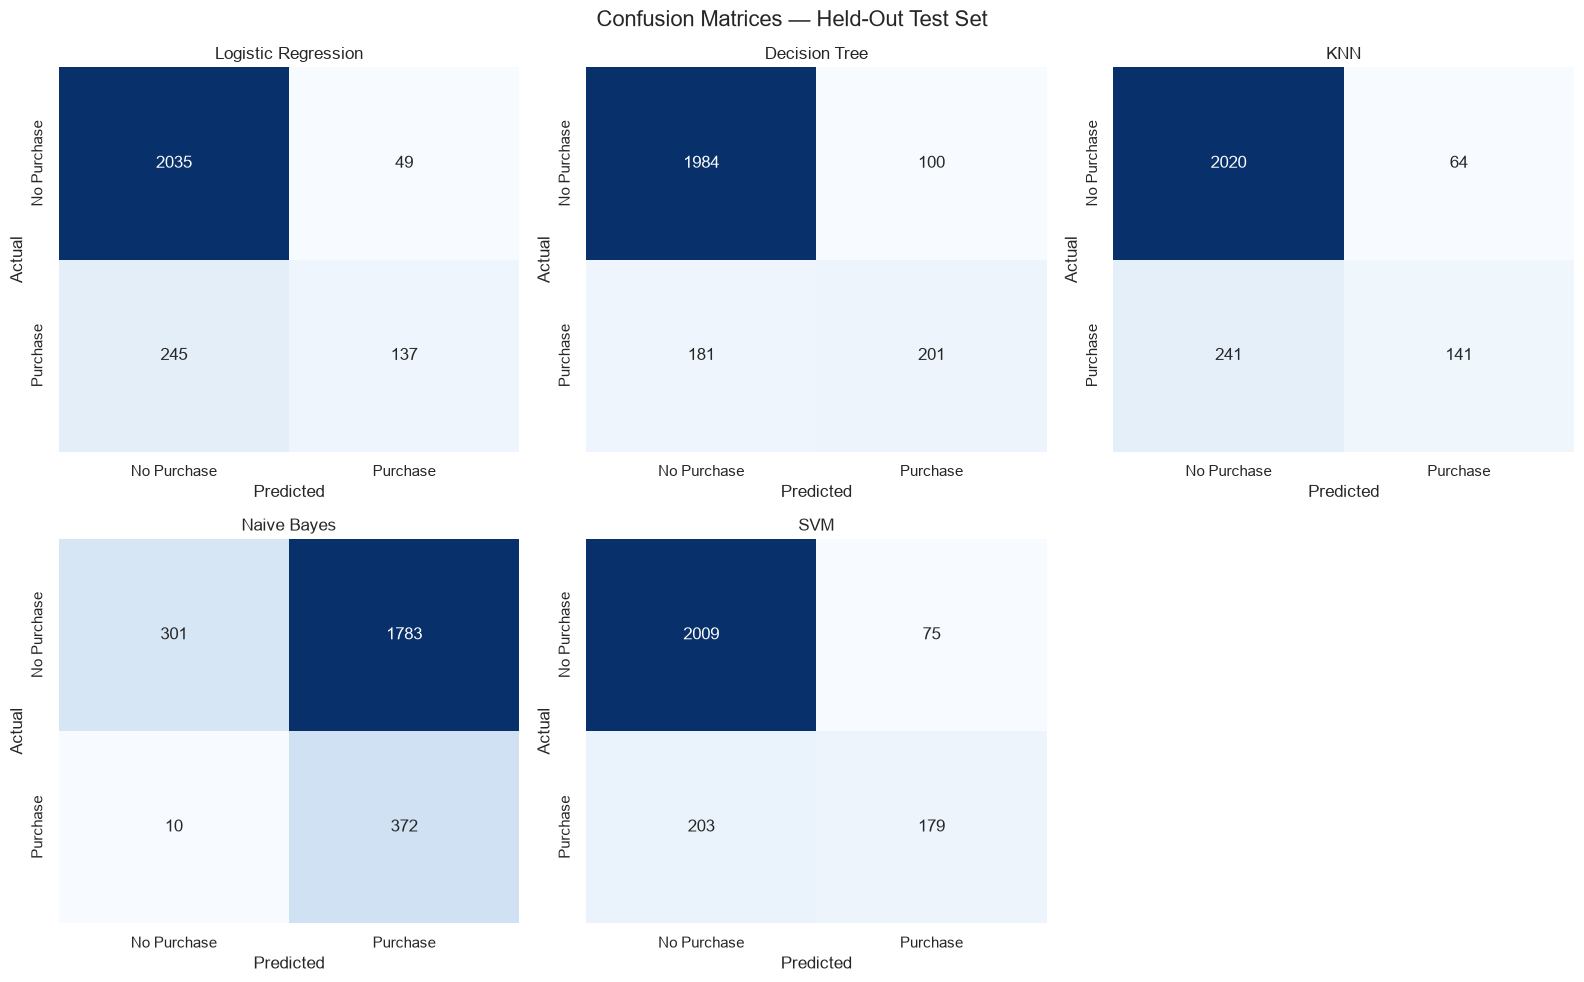


Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.89      0.98      0.93      2084
    Purchase       0.74      0.36      0.48       382

    accuracy                           0.88      2466
   macro avg       0.81      0.67      0.71      2466
weighted avg       0.87      0.88      0.86      2466


Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.92      0.95      0.93      2084
    Purchase       0.67      0.53      0.59       382

    accuracy                           0.89      2466
   macro avg       0.79      0.74      0.76      2466
weighted avg       0.88      0.89      0.88      2466


KNN
              precision    recall  f1-score   support

 No Purchase       0.89      0.97      0.93      2084
    Purchase       0.69      0.37      0.48       382

    accuracy                           0.88      2466
   macro avg       0.79      0.67      0.71      2466
weighted avg       0.86      0.88

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
for idx, (name, pipeline) in enumerate(trained_pipelines.items()):
    predictions = pipeline.predict(X_test)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No Purchase", "Purchase"],
                yticklabels=["No Purchase", "Purchase"], ax=axes[idx])
    axes[idx].set_title(name)
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")
fig.delaxes(axes[-1])
plt.suptitle("Confusion Matrices — Held-Out Test Set", fontsize=16)
plt.tight_layout()
plt.show()

for name, pipeline in trained_pipelines.items():
    print("\n" + "=" * 55)
    print(name)
    print(classification_report(y_test, pipeline.predict(X_test),
                                labels=[0, 1],
                                target_names=["No Purchase", "Purchase"],
                                zero_division=0))

## 12. ROC curves and AUC

The ROC curve plots **true-positive rate** against **false-positive rate** as the decision threshold changes. AUC measures discrimination across thresholds. AUC is calculated from model scores/probabilities, never from binary class predictions.

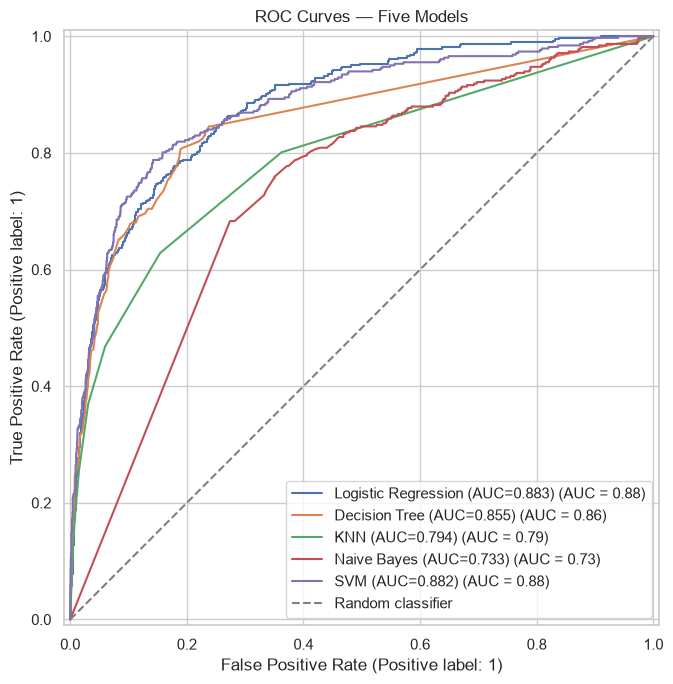

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
for name, pipeline in trained_pipelines.items():
    RocCurveDisplay.from_predictions(
        y_test,
        pipeline.predict_proba(X_test)[:, 1],
        name=f"{name} (AUC={results_df.loc[name, 'AUC']:.3f})",
        ax=ax
    )
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random classifier")
ax.set_title("ROC Curves — Five Models")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 13. Save the labeled test CSV

The assignment requires a **test CSV containing all 17 input features plus the target**. We export the held-out test partition only, preserving the exact feature names and their original representations. The Streamlit app will load the saved `.joblib` pipeline and evaluate this CSV **without refitting**.

Do not upload the entire training dataset to the Streamlit free-tier application.

In [13]:
test_data = X_test.copy()
test_data["Revenue"] = y_test.astype(bool)
TEST_FILE = PROJECT_ROOT / "test_data.csv"
test_data.to_csv(TEST_FILE, index=False)

assert test_data.shape[1] == 18
assert len(test_data) == len(X_test)
print("Saved test CSV:", TEST_FILE)
print("Shape:", test_data.shape)
display(test_data.head())

Saved test CSV: C:\Users\hp\Desktop\2026aj05667\test_data.csv
Shape: (2466, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
4722,1,4.0,0,0.0,13,161.166667,0.024615,0.061538,0.000000,0.6,May,2,5,9,5,Returning_Visitor,False,False
6835,1,23.2,0,0.0,23,290.000000,0.000000,0.033333,0.000000,0.0,Jul,2,2,8,3,Returning_Visitor,False,False
5524,0,0.0,0,0.0,6,95.000000,0.028571,0.028571,86.336233,0.0,Oct,1,1,4,2,New_Visitor,False,True
663,0,0.0,0,0.0,2,17.000000,0.000000,0.100000,0.000000,0.0,Mar,1,1,8,3,Returning_Visitor,False,False
136,0,0.0,0,0.0,9,303.666667,0.005556,0.046296,0.000000,0.0,Feb,2,4,5,2,Returning_Visitor,False,False


## 14. Save comparison results and metadata

These files will be useful for the customized Streamlit dashboard and README. The app will still recompute metrics on any **uploaded labeled test CSV**, rather than trusting the stored comparison table.

In [14]:
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(exist_ok=True)
comparison.to_csv(REPORT_DIR / "model_comparison.csv")

metadata = {
    "target_column": "Revenue",
    "positive_class": 1,
    "feature_columns": X.columns.tolist(),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "test_rows": len(X_test),
    "split_random_state": RANDOM_STATE,
    "model_files": model_filenames,
}
with (MODEL_DIR / "metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved comparison CSV and model metadata")

Saved comparison CSV and model metadata


## 15. Verify a saved model can evaluate the test CSV without retraining

This simulates the Streamlit workflow. We load a saved pipeline, read the exported test CSV, and call **predict** / **predict_proba** only. We do **not** call `.fit()` on the uploaded test set.

**Security note:** Only load `.joblib` files you created or trust; pickle/joblib loading can execute arbitrary code.

In [15]:
loaded_test = pd.read_csv(TEST_FILE)
loaded_X = loaded_test[X.columns.tolist()]
loaded_y = loaded_test["Revenue"].astype(int)

loaded_pipeline = joblib.load(MODEL_DIR / "logistic_regression.joblib")
loaded_pred = loaded_pipeline.predict(loaded_X)
loaded_prob = loaded_pipeline.predict_proba(loaded_X)[:, 1]

print("Saved pipeline accuracy:", round(accuracy_score(loaded_y, loaded_pred), 4))
print("Saved pipeline AUC:", round(roc_auc_score(loaded_y, loaded_prob), 4))
print("No retraining performed during verification.")

Saved pipeline accuracy: 0.8808
Saved pipeline AUC: 0.8828
No retraining performed during verification.


## 16. Model observations — fill after execution

The assignment asks for an observation for **each of the five models** and an **overall winner**. Use the actual results above to write your own conclusions.

| Model | Questions to answer |
|---|---|
| Logistic Regression | Does the linear baseline offer good precision/recall? |
| Decision Tree | Does its nonlinearity improve results? Is performance stable? |
| KNN | Does it struggle with one-hot encoded feature space? |
| Gaussian Naive Bayes | Is recall high at the expense of precision? |
| SVM | Does it improve AUC or F1? What is its training cost? |
| Overall winner | Which model best matches the business objective, supported by multiple metrics? |

**Important:** The held-out test set is for evaluation, not repeated hyperparameter selection. If you decide to tune parameters, use cross-validation on the training split, then evaluate the final selection once on the test set.

### Streamlit UI — upcoming phase

Business Analytics Pro will use a light theme, blue/purple highlights, labeled test CSV upload, model dropdown, six KPI metrics, confusion matrix, classification report, and comparison chart. The app must **load saved pipelines**, not train on uploaded data.

## 17. Git commit #3 — model development

After running all cells and checking outputs, review the changed files in VS Code and commit this phase separately from the earlier EDA work.

```bash
# From the project root
git status
git add notebooks/02_model_development.ipynb requirements.txt src/ model/ test_data.csv reports/
git diff --cached --stat
git commit -m "feat: train and evaluate five classifiers with saved pipelines"
git push origin main
```

**Before committing:** ensure that `src/` exists (it was created in Step 1), update `requirements.txt`, verify model files are reasonably sized, and check that the staged files contain no secrets or unintended data. Git ignores empty directories. If `src/` has no new changes, it can be omitted from `git add`.

**Next:** Build `app.py`, `.streamlit/config.toml`, and a customized Business Analytics Pro interface that loads the saved models and scores user-uploaded labeled test CSVs.